# 06 — Final Model Evaluation (Random Forest)

The 118th Congress has been held out since the start of the project. This notebook:
1. Rebuilds the final random forest with the hyperparameters and class weights chosen on **109th–117th CV only**
2. Fits it once on all of 109–117
3. Scores it **once** on the 118th Congress
4. Saves predictions, metrics, importances, and the fitted model to `results/` for the app

In [16]:
import sys; sys.path.append("../src/models")
from model_setup import *

import numpy as np
import pandas as pd
import json
import joblib
import sklearn
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import accuracy_score, balanced_accuracy_score

FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__) # for app requirements file later

scikit-learn 1.9.1


In [8]:
# rebuilding final model
params = joblib.load(RES / "rf_grid_best_params.pkl")
params = {k.replace("clf__", ""): v for k, v in params.items()}# stripping pipeline prefix

final_pipe = Pipeline([
    ("prep", clone(prep_tree)),
    ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **params))
])

weights = np.asarray(joblib.load(RES / "rf_class_weights.pkl"), dtype=float)

print("hyperparameters:", params)
print("class weights (dided, passed, law):", weights)


hyperparameters: {'class_weight': 'balanced_subsample', 'max_depth': 40, 'max_features': 'sqrt', 'min_samples_leaf': 5}
class weights (dided, passed, law): [1. 1. 1.]


In [9]:
print("train:", X_train.shape, "| congresses", sorted(train['congress'].unique()))
print("test: ", X_test.shape, " | congresses", sorted(test["congress"].unique()))
assert set(train["congress"]).isdisjoint(set(test["congress"]))

shares = pd.DataFrame({
    "train (109-117)": y_train.value_counts(normalize=True),
    "test (118)": y_test.value_counts(normalize=True),
}).rename(index=SHORT).round(3)
shares

train: (101684, 50) | congresses [np.int64(109), np.int64(110), np.int64(111), np.int64(112), np.int64(113), np.int64(114), np.int64(115), np.int64(116), np.int64(117)]
test:  (16495, 50)  | congresses [np.int64(118)]


,train (109-117),test (118)
outcome,,
died,0.914,0.942
passed,0.053,0.042
law,0.033,0.016


# Fitting Once

In [10]:
final_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](50,)","['n_original_cosponsors','days_left_in_congress','nominate_dim1',..., 'sponsor_pres_party','other_chamber_same_party','sponsor_trifecta']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,50
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('rest', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

# predicting 118th

In [12]:
proba = final_pipe.predict_proba(X_test)
assert list(final_pipe.classes_) == list(CLASSES) # columns have to be died, passed, law for weights to line up

pred_argmax = CLASSES[proba.argmax(axis=1)]
pred = CLASSES[(proba * weights).argmax(axis=1)]
print("predictions changed by weighting:", int((pred != pred_argmax).sum()))

predictions changed by weighting: 0


Weights ended up being 1 for random forest, so naturally none changed. LOL! my bad.

# metrics

In [18]:
def summarize(y_true, y_pred, proba_law):
    return {"f1_macro": f1_score(y_true, y_pred, average="macro"),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "acc": accuracy_score(y_true, y_pred),
            "ap_law": average_precision_score(y_true == 3, proba_law)}

dummy_pred = np.full(len(y_test), 1) # always predict "died"
dummy_law = np.full(len(y_test), (y_train == 3).mean()) # same P(law) for every bill

metrics = pd.DataFrame({
    "RF: 118th (test)": summarize(y_test, pred, proba[:, 2]),
    "Always died: 118th (test)": summarize(y_test, dummy_pred, dummy_law)
}).T.round(3)

cv = pd.read_csv(RES / "model_comparison.csv").set_index("model")
metrics.loc["RF: 109-117 CV", ["f1_macro", "ap_law"]] = cv.loc["rf", ["f1_tuned", "ap_law"]].astype(float).round(3).values
metrics

,f1_macro,bal_acc,acc,ap_law
RF: 118th (test),0.494,0.489,0.926,0.304
Always died: 118th (test),0.323,0.333,0.942,0.016
RF: 109-117 CV,0.513,NaN,NaN,0.317


# per class report

In [20]:
print(classification_report(y_test, pred, labels=CLASSES,
                            target_names=[SHORT[c] for c in CLASSES], zero_division=0))


              precision    recall  f1-score   support

        died       0.96      0.97      0.96     15538
      passed       0.23      0.14      0.17       685
         law       0.33      0.36      0.34       272

    accuracy                           0.93     16495
   macro avg       0.51      0.49      0.49     16495
weighted avg       0.91      0.93      0.92     16495



# Confusion Matrices

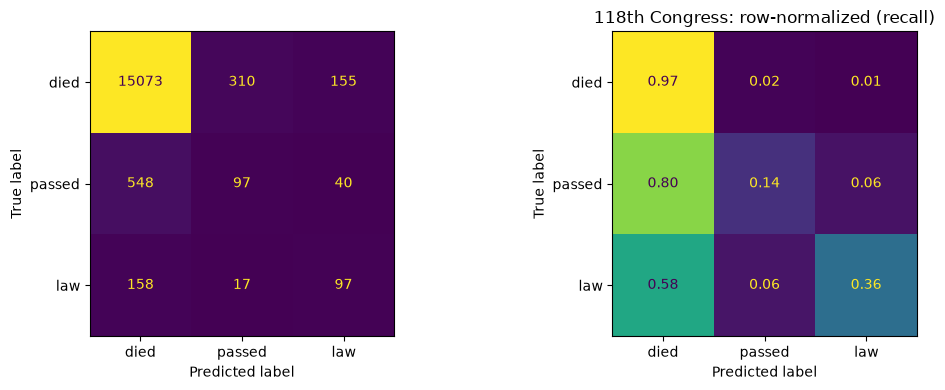

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, norm, title in zip(axes, [None, "true"], ["counts", "row-normalized (recall)"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=CLASSES, normalize=norm,
        display_labels=[SHORT[c] for c in CLASSES],
        values_format=".2f" if norm else "d", ax=ax, colorbar=False)

ax.set_title(f"118th Congress: {title}")
plt.tight_layout()
plt.savefig(FIG / "final_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Precision among top-ranked bills for "law"

In [23]:
base_rate = (y_test == 3).mean()
order = np.argsort(-proba[:, 2]) # highest P(law ) first
is_law = (y_test.values == 3)

topk = pd.DataFrame([
    {"k": k, "laws_in_top_k": int(is_law[order[:k]].sum()), "precision_at_k": is_law[order[:k]].mean()}
    for k in [50, 100, 250, 500, 1000]
])

topk["lift_vs_random"] = (topk["precision_at_k"] / base_rate).round(1)
print(f"base rate of law in the 118th: {base_rate:.3f}")
topk

base rate of law in the 118th: 0.016


,k,laws_in_top_k,precision_at_k,lift_vs_random
0,50,34,0.680,41.2
1,100,61,0.610,37.0
2,250,93,0.372,22.6
3,500,120,0.240,14.6
4,1000,149,0.149,9.0


# Permutation Importance

In [26]:
perm = permutation_importance(final_pipe, X_test, y_test, scoring=ap_law,
                              n_repeats=5, random_state=SEED)

imp = (pd.DataFrame({"feature": FEATURES,
                    "importance_mean": perm.importances_mean,
                    "importance_std": perm.importances_std}).sort_values("importance_mean", ascending=False)
.reset_index(drop=True))

imp.head(15)

,feature,importance_mean,importance_std
0,t_designate,0.035929,0.003184
1,title_n_words,0.031434,0.008357
2,commemorative,0.020901,0.002210
3,n_original_bipartisan,0.018107,0.003747
4,n_original_cosponsors,0.016318,0.004061
5,policy_area,0.013635,0.006602
6,is_bipartisan,0.010154,0.003941
7,days_left_in_congress,0.009995,0.007012
8,type,0.006805,0.004757
9,has_short_title,0.006364,0.004769


# importance plot

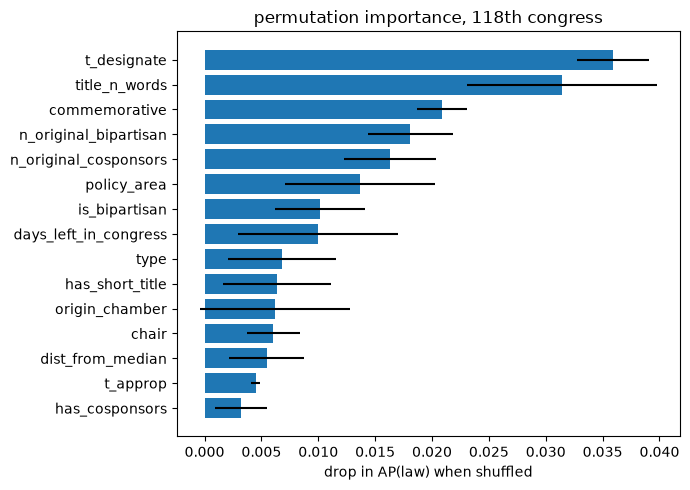

In [27]:
top = imp.head(15).iloc[::-1] # reversing so biggest bar on top
fig, ax = plt.subplots(figsize=(7,5))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
ax.set_xlabel("drop in AP(law) when shuffled")
ax.set_title("permutation importance, 118th congress")
plt.tight_layout()
plt.savefig(FIG / "final_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

# partial dependence for top 3 numeric features

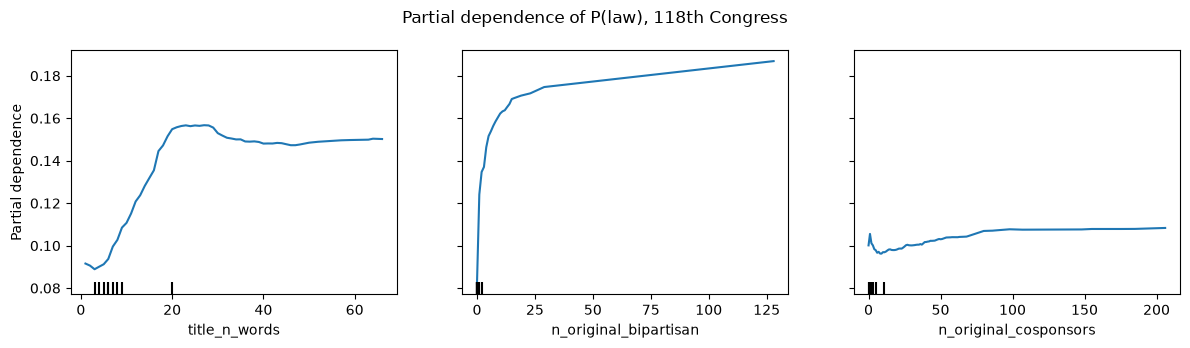

features plotted ['title_n_words', 'n_original_bipartisan', 'n_original_cosponsors']


In [28]:
top_num = [f for f in imp["feature"] if f in NUM][:3]
X_pdp = X_test.sample(3000, random_state=SEED).astype({f: float for f in top_num})

fig, ax = plt.subplots(figsize=(12, 3.5))
PartialDependenceDisplay.from_estimator(final_pipe, X_pdp, features=top_num, target=3,
                                        kind="average", ax=ax)
fig.suptitle("Partial dependence of P(law), 118th Congress")
plt.tight_layout()
plt.savefig(FIG / "final_partial_dependence.png", dpi=200, bbox_inches="tight")
plt.show()
print("features plotted", top_num)

In [29]:
# save everything for app
out = test[["bill_id", "congress", "title", "type", "origin_chamber",
            "sponsor_party", "policy_area", "outcome"]].copy()
out[["p_died", "p_passed", "p_law"]] = proba
out["pred"] = pred
out.to_csv(RES / "test_predictions.csv", index=False)

metrics.to_csv(RES / "test_metrics.csv")
topk.to_csv(RES / "test_precision_at_k.csv", index=False)
imp.to_csv(RES / "permutation_importance.csv", index=False)

defaults = {c: float(X_train[c].median()) for c in NUM}
defaults.update({c: X_train[c].mode().iloc[0] for c in CAT + BIN})
defaults = {k: (v.item() if hasattr(v, "item") else v) for k, v in defaults.items()}   # numpy -> plain Python for JSON
with open(RES / "feature_defaults.json", "w") as f:
    json.dump(defaults, f, indent=2)

joblib.dump({"pipeline": final_pipe, "weights": weights, "features": FEATURES,
             "classes": CLASSES, "model": "rf", "sklearn_version": sklearn.__version__},
            RES / "final_model.joblib", compress=3)

for f in ["test_predictions.csv", "feature_defaults.json", "final_model.joblib"]:
    print(f, f"{(RES / f).stat().st_size / 1e6:.1f} MB")

test_predictions.csv 2.8 MB
feature_defaults.json 0.0 MB
final_model.joblib 74.5 MB
